## Student Perfonace Indecator

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("data/student.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.shape

(1000, 8)

In [5]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [7]:
df.duplicated().sum()

np.int64(0)

## Checking the no of unique values of each column

In [8]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [9]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [10]:
print("Categories in 'gender' variable:" ,end=" ")
print(df["gender"].unique())
print("Categories in 'race/ethnicity' variable:" ,end=" ")
print(df["race/ethnicity"].unique())
print("Categories in 'parental level of education' variable:" ,end=" ")
print(df["parental level of education"].unique())
print("Categories in 'lunch' variable:" ,end=" ")
print(df["lunch"].unique())
print("Categories in 'test preparation course' variable:" ,end=" ")
print(df["test preparation course"].unique())

Categories in 'gender' variable: <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable: <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [11]:
print(df.dtypes)

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object


In [12]:
# Numerical features
numeric_features = df.select_dtypes(include=['number']).columns.tolist()

# Categorical features
categorical_features = df.select_dtypes(
    include=['object', 'category', 'string', 'str']
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['math score', 'reading score', 'writing score']
Categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [13]:
df.head(2)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88


In [14]:
df["total score"]=df["math score"]+df["reading score"]+df["writing score"]
df["average score"]=df["total score"]/3
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total score,average score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [15]:
reading_full = df[df['reading score'] == 100]['average score'].count()

writing_full = df[df['writing score'] == 100]['average score'].count()

math_full = df[df['math score'] == 100]['average score'].count()



reading_less_20 = df[df['reading score'] <= 20]['average score'].count()

writing_less_20 = df[df['writing score'] <= 20]['average score'].count()

math_less_20 = df[df['math score'] <= 20]['average score'].count()

In [16]:
# Full marks
print("Maths:", (df['math score'] == 100).sum())
print("Reading:", (df['reading score'] == 100).sum())
print("Writing:", (df['writing score'] == 100).sum())

# Marks <= 20
print("Maths:", (df['math score'] <= 20).sum())
print("Reading:", (df['reading score'] <= 20).sum())
print("Writing:", (df['writing score'] <= 20).sum())

Maths: 7
Reading: 17
Writing: 14
Maths: 4
Reading: 1
Writing: 3


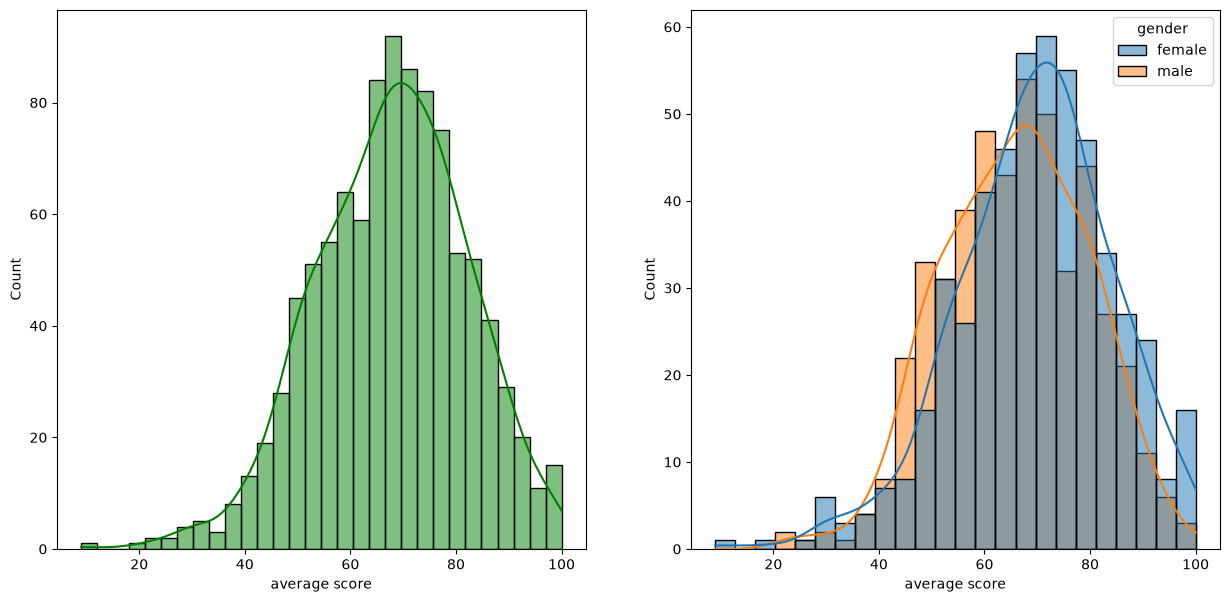

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

plt.subplot(121)
sns.histplot(data=df, x='average score', bins=30, kde=True, color='g')

plt.subplot(122)
sns.histplot(data=df, x='average score', kde=True, hue='gender')

plt.show()

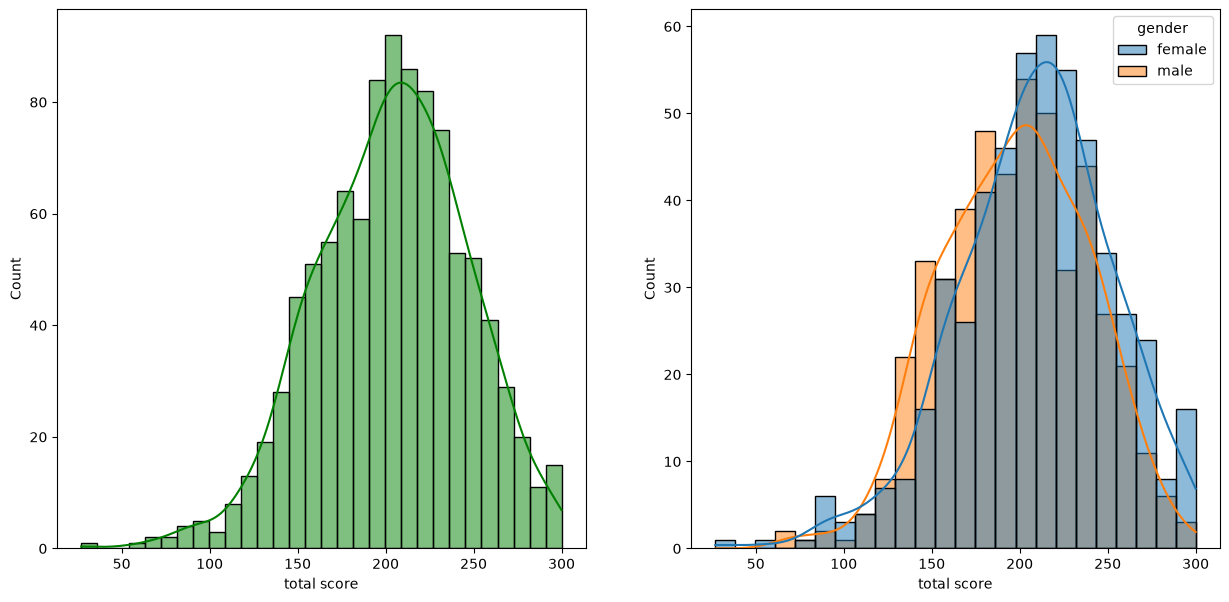

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

plt.subplot(121)
sns.histplot(data=df, x='total score', bins=30, kde=True, color='g')

plt.subplot(122)
sns.histplot(data=df, x='total score', kde=True, hue='gender')

plt.show()

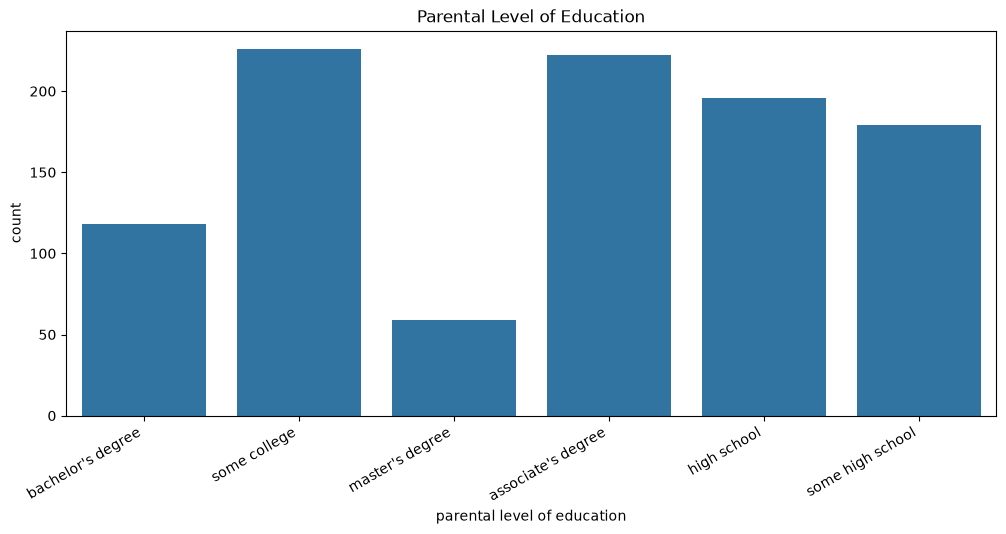

In [19]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x='parental level of education'
)

plt.xticks(rotation=30, ha='right')
plt.title('Parental Level of Education')
plt.show()

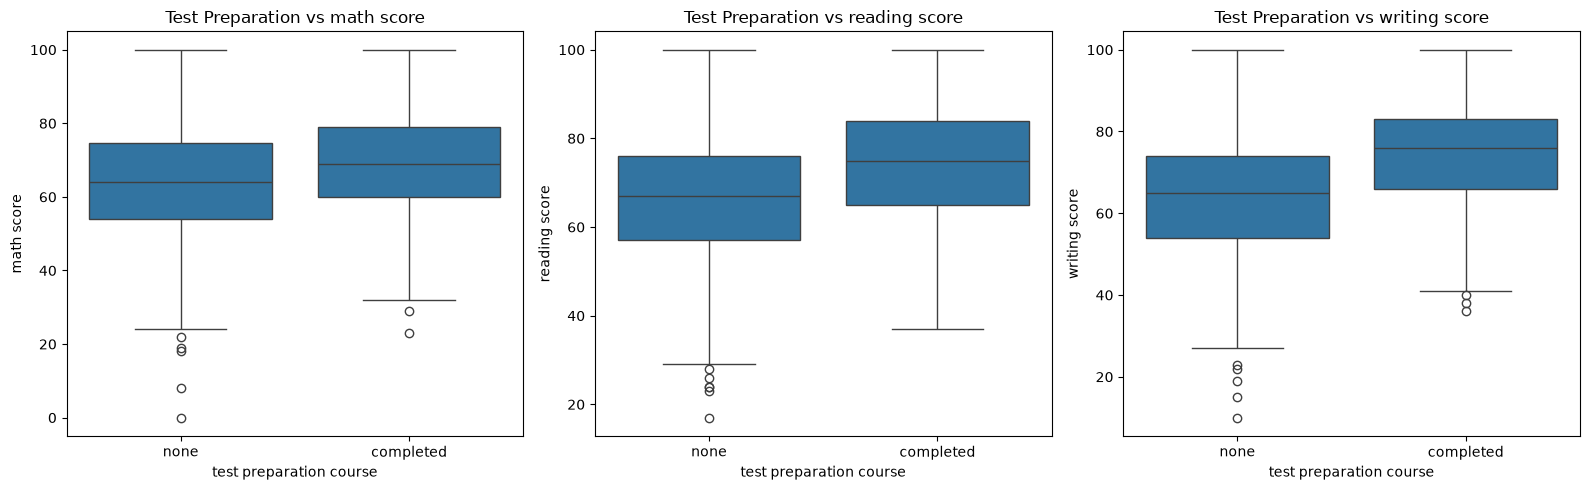

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(
    axs,
    ['math score', 'reading score', 'writing score']
):

    sns.boxplot(
        data=df,
        x='test preparation course',
        y=col,
        ax=ax
    )

    ax.set_title(f'Test Preparation vs {col}')

plt.tight_layout()
plt.show()

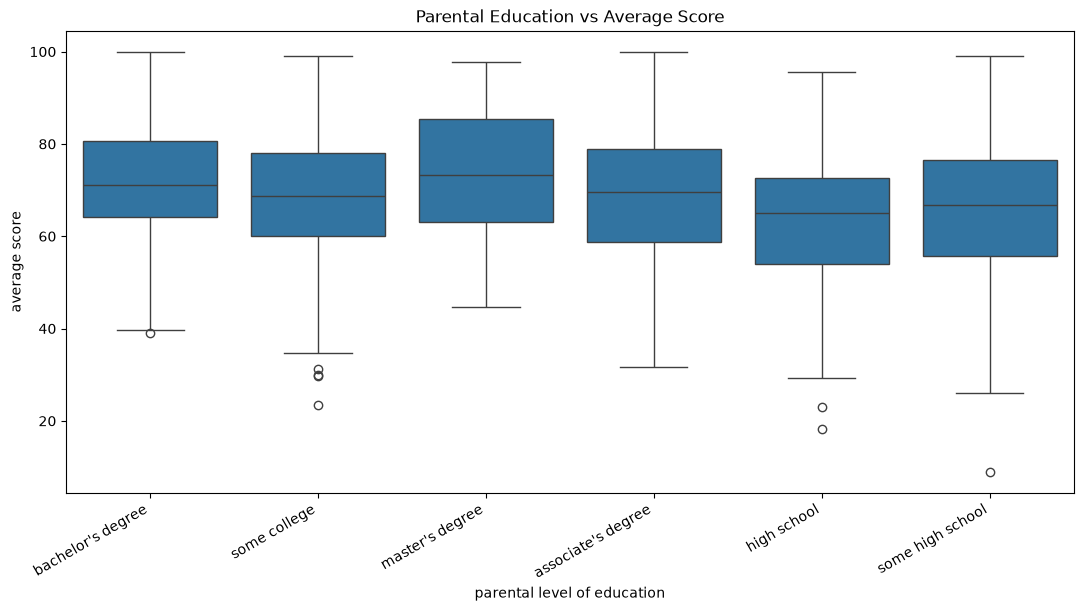

In [21]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df,
    x='parental level of education',
    y='average score'
)

plt.xticks(rotation=30, ha='right')
plt.title('Parental Education vs Average Score')
plt.show()

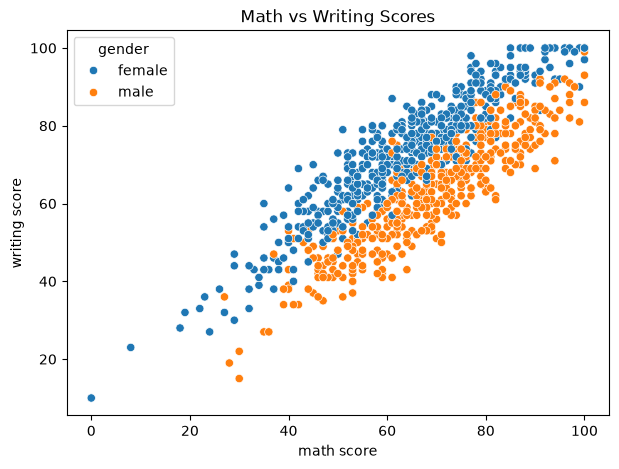

In [22]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x='math score',
    y='writing score',
    hue='gender'
)

plt.title('Math vs Writing Scores')
plt.show()

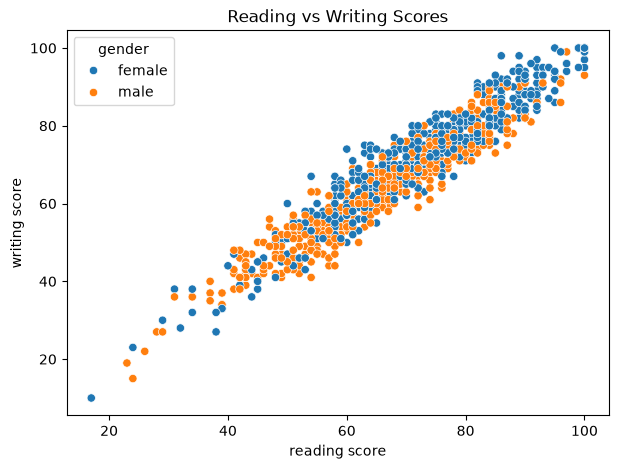

In [23]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x='reading score',
    y='writing score',
    hue='gender'
)

plt.title('Reading vs Writing Scores')
plt.show()

In [24]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score', 'total score', 'average score'],
      dtype='str')

In [25]:
def performance_category(score):

    if score >= 80:
        return 'Excellent'

    elif score >= 60:
        return 'Good'

    elif score >= 40:
        return 'Average'

    else:
        return 'Needs Improvement'


df['performance'] = df['average score'].apply(
    performance_category
)

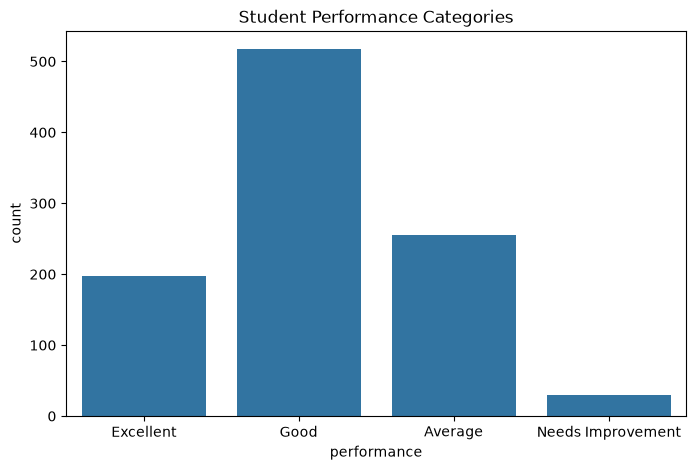

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='performance',
    order=[
        'Excellent',
        'Good',
        'Average',
        'Needs Improvement'
    ]
)

plt.title('Student Performance Categories')
plt.show()

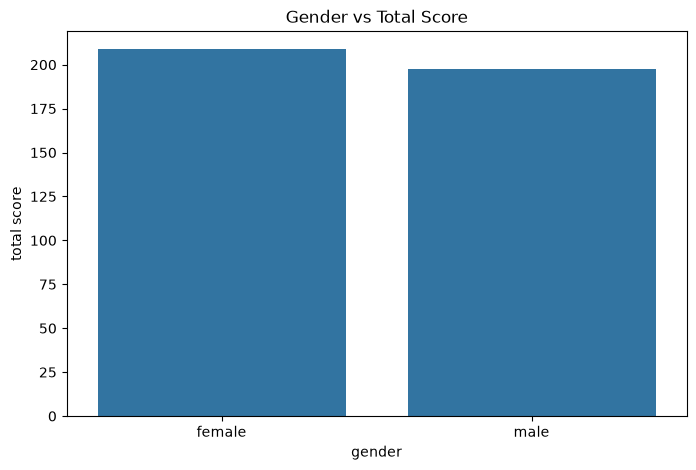

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='gender',
    y='total score',
    errorbar=None
)

plt.title('Gender vs Total Score')
plt.show()

In [28]:
def performance_category(score):

    if score >= 80:
        return 'Excellent'

    elif score >= 60:
        return 'Good'

    elif score >= 40:
        return 'Average'

    else:
        return 'Needs Improvement'


df['performance'] = df['average score'].apply(
    performance_category
)

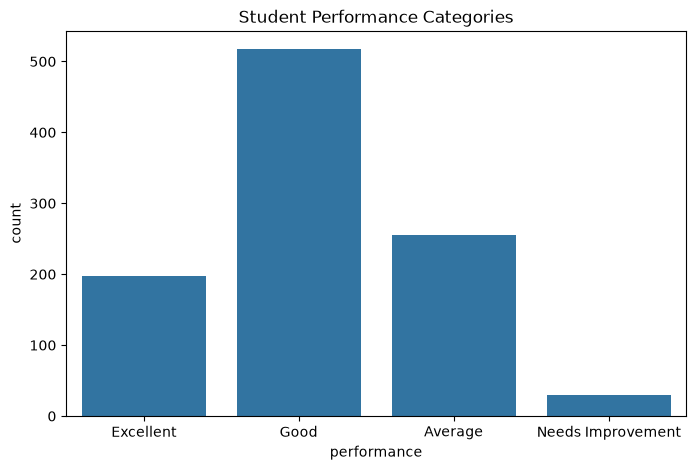

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='performance',
    order=[
        'Excellent',
        'Good',
        'Average',
        'Needs Improvement'
    ]
)

plt.title('Student Performance Categories')
plt.show()

In [30]:
print("Total Students:", len(df))

print("\nAverage Scores:")
print(df[numeric_features].mean())

print("\nMaximum Scores:")
print(df[numeric_features].max())

print("\nMinimum Scores:")
print(df[numeric_features].min())

print("\nGender-wise Average Score:")
print(
    df.groupby('gender')['average score'].mean()
)

print("\nTest Preparation vs Average Score:")
print(
    df.groupby('test preparation course')['average score'].mean()
)

print("\nLunch vs Average Score:")
print(
    df.groupby('lunch')['average score'].mean()
)

print("\nParental Education vs Average Score:")
print(
    df.groupby('parental level of education')['average score'].mean()
)

Total Students: 1000

Average Scores:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

Maximum Scores:
math score       100
reading score    100
writing score    100
dtype: int64

Minimum Scores:
math score        0
reading score    17
writing score    10
dtype: int64

Gender-wise Average Score:
gender
female    69.569498
male      65.837483
Name: average score, dtype: float64

Test Preparation vs Average Score:
test preparation course
completed    72.669460
none         65.038941
Name: average score, dtype: float64

Lunch vs Average Score:
lunch
free/reduced    62.199061
standard        70.837209
Name: average score, dtype: float64

Parental Education vs Average Score:
parental level of education
associate's degree    69.569069
bachelor's degree     71.923729
high school           63.096939
master's degree       73.598870
some college          68.476401
some high school      65.108007
Name: average score, dtype: float64
